In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [116]:
# functions

## x-axis values spanning from 0 to 5 (N*dx)

lowbound = -1
upbound = 5
dx = 0.0002
N = (upbound-lowbound)//dx

xs = np.arange(start=lowbound, stop=upbound, step=dx)

## polynomial
def func1(xs):
    return xs

## sinusoid
def func2(xs):
    return np.sin(2*np.pi*xs)

11.999000019996696


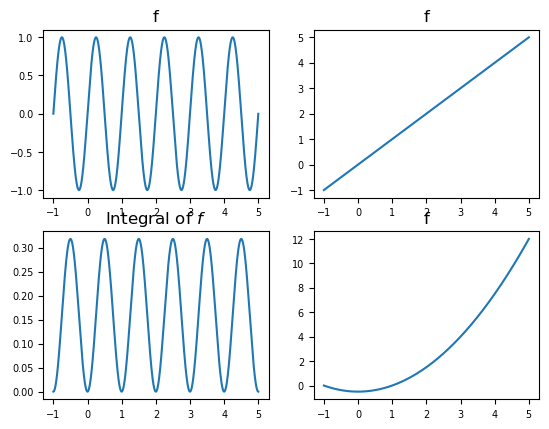

In [117]:
# trapezoid integrator
def trapezoid_integrator(xs, func):
    dx = xs[1]-xs[0]
    cont = np.array([])
    cont2 = np.array([])
    for i in range(len(xs)-1):
        a = func(xs[i])
        b = func(xs[i+1])
        dy = 0.5*dx*(a+b)
        cont = np.append(cont, dy)
        n = np.sum(cont)
        cont2 = np.append(cont2, n)
    return (cont2, np.sum(cont))  # cont2 graphs indf. integ; sum takes def. integ.


## calling the trapezoid integrator
ys = trapezoid_integrator(xs, func2)[0]

ys2 = trapezoid_integrator(xs, func1)[0]



## graphing
fig, ((ax,ax2),(ax3,ax4)) = plt.subplots(2,2)

ax.plot(xs, func2(xs))
ax.tick_params(labelsize=7)
ax.set_title("f")

ax3.plot(xs[:-1], ys)
ax3.tick_params(labelsize=7)
ax3.set_title("Integral of $f$")

ax2.plot(xs, func1(xs))
ax2.tick_params(labelsize=7)
ax2.set_title("f")

ax4.plot(xs[:-1], ys2)
ax4.tick_params(labelsize=7)
ax4.set_title("f")

print(trapezoid_integrator(xs, func1)[1])

0.056138479532157566

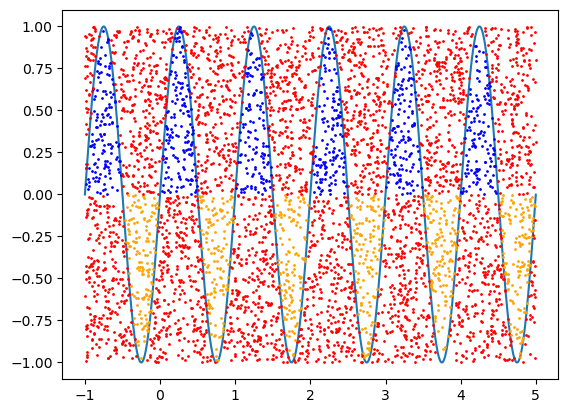

In [118]:
# monte carlo integrator

#rng seed
rng = np.random.default_rng()


## defining point generator function
def rnd(x,y):
    xlow = np.min(x)
    xhigh = np.max(x)
    ylow = np.min(y)
    yhigh = np.max(y)
    return (rng.uniform(xlow, xhigh), rng.uniform(ylow, yhigh))


## monte carlo with plot
fig, ax = plt.subplots()

def signed_montecarlo_integrator(xs, func, N):
    ### important constants
    pos = 0
    neg = 0
    reject = 0
    area = (np.max(xs)-np.min(xs))*(np.max(func(xs))-np.min(func(xs)))

    ### plotting the function
    ax.plot(xs, func(xs))
    
    for i in range(N):
        point = rnd(xs, func(xs))


        if point[1] > 0:  # points on the upper half
            if point[1] > func(point[0]):
                reject += 1
                ax.plot(point[0], point[1], 'o', markersize=1, color = "red")

            else:
                pos += 1
                ax.plot(point[0], point[1], 'o', markersize=1, color = "blue")
        
        else:   # points on the upper half
            if point[1] >= func(point[0]):
                neg += 1
                ax.plot(point[0], point[1], 'o', markersize=1, color = "orange")

            else:
                reject += 1
                ax.plot(point[0], point[1], 'o', markersize=1, color = "red")

    accept = pos - neg
    integral = (accept/(accept + reject))*area
    return integral

## testing
signed_montecarlo_integrator(xs, func2, 5000)


In [113]:
# 1/3 Simpson's rule integrator

def onethird_simpson_integrator(xs, func):
    return 

In [126]:
# Gezerlis implementation

def simpson(func, a, b, n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    cs = 2*np.ones(n)
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1
    contribs = cs*func(xs)
    return (h/3)*np.sum(contribs)

## test

simpson(func1, 0, 5, 25000)

12.499666659999997